- Target variable - Incurred (final cost of the claim = all payments made by the insurer)
> - At stage 1, the model learns from the available claim descriptions and other available information to predict 'Incurred' and at stage 2, converts predicted cost into low, medium or high priority using MAE, RMSE and R2.
- Problem - multi-class classification problem

# **Import Libraries**

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# **Data Collection**

In [3]:
df = pd.read_csv("DR_Demo_Statistical_Case_Estimates.csv")

In [4]:
df.head()

,ReportingDelay,AccidentHour,Age,WeeklyRate,Gender,MaritalStatus,HoursWorkedPerWeek,DependentChildren,DependentsOther,PartTimeFullTime,DaysWorkedPerWeek,DateOfAccident,ClaimDescription,ReportedDay,InitialCaseEstimate,Incurred
0,15,11,28,500.00,M,S,44.0,0,0,F,5,5/10/2005,STRUCK SCAFFOLDING STRAIN LOWER BACK,3Thurs,9500,151.254501
1,22,5,29,500.00,M,S,38.0,0,0,F,5,28/10/2003,STRUCK KNIFE LACERATED LEFT THUMB,2Wed,11500,442.125024
2,22,7,28,197.37,M,M,16.0,0,0,P,3,25/05/2004,SLIPPED AND HIT STRAINED LEFT SHOULDER INJURY ...,2Wed,8000,1494.490505
3,15,12,40,0.00,M,M,0.0,1,0,F,5,21/07/1994,HIT FALLING DOOR LACERATION LEFT SHOULDER INJU...,4Fri,500,138.900000
4,38,12,22,435.70,M,M,38.0,0,0,F,5,9/06/1992,STRUCK FALLING OBJECT LACERATION RIGHT RING FI...,4Fri,320,296.160000


In [5]:
df.tail()

,ReportingDelay,AccidentHour,Age,WeeklyRate,Gender,MaritalStatus,HoursWorkedPerWeek,DependentChildren,DependentsOther,PartTimeFullTime,DaysWorkedPerWeek,DateOfAccident,ClaimDescription,ReportedDay,InitialCaseEstimate,Incurred
21686,23,9,53,200.00,M,M,38.0,0,0,F,5,18/06/2000,STRUCK KNIFE CUT RIGHT HAND CUT,1Tues,2650,582.166718
21687,15,13,23,500.00,M,S,40.0,0,0,F,5,23/06/2004,STRUCK WITH HAMMER FRACTURE RIGHT MIDDLE FINGER,3Thurs,1000,908.635098
21688,109,12,19,200.00,M,S,38.0,0,0,F,5,6/01/1996,STRUCK METAL GRINDING FOREIGN BODY LEFT BODY L...,2Wed,814,60.250000
21689,7,9,34,553.13,M,S,38.0,0,0,F,5,5/12/1996,STRUCK MOVING STEEL LACERATION LEFT KNEE LEFT ...,3Thurs,1500,761.625000
21690,8,11,23,200.00,M,S,38.0,0,0,F,5,16/05/2002,LIFTING BACK STRAIN LOWER BACK STRAIN LOWER BACK,4Fri,10700,1853.010547


# **Data Cleaning**

In [6]:
df.shape

(21691, 16)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 21691 entries, 0 to 21690
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ReportingDelay       21691 non-null  int64  
 1   AccidentHour         21691 non-null  int64  
 2   Age                  21691 non-null  int64  
 3   WeeklyRate           21691 non-null  float64
 4   Gender               21691 non-null  str    
 5   MaritalStatus        21669 non-null  str    
 6   HoursWorkedPerWeek   21691 non-null  float64
 7   DependentChildren    21691 non-null  int64  
 8   DependentsOther      21691 non-null  int64  
 9   PartTimeFullTime     21691 non-null  str    
 10  DaysWorkedPerWeek    21691 non-null  int64  
 11  DateOfAccident       21691 non-null  str    
 12  ClaimDescription     21691 non-null  str    
 13  ReportedDay          21691 non-null  str    
 14  InitialCaseEstimate  21691 non-null  int64  
 15  Incurred             21691 non-null  float64
dt

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.dtypes

ReportingDelay           int64
AccidentHour             int64
Age                      int64
WeeklyRate             float64
Gender                     str
MaritalStatus              str
HoursWorkedPerWeek     float64
DependentChildren        int64
DependentsOther          int64
PartTimeFullTime           str
DaysWorkedPerWeek        int64
DateOfAccident             str
ClaimDescription           str
ReportedDay                str
InitialCaseEstimate      int64
Incurred               float64
dtype: object

In [10]:
df.isnull().sum()

ReportingDelay          0
AccidentHour            0
Age                     0
WeeklyRate              0
Gender                  0
MaritalStatus          22
HoursWorkedPerWeek      0
DependentChildren       0
DependentsOther         0
PartTimeFullTime        0
DaysWorkedPerWeek       0
DateOfAccident          0
ClaimDescription        0
ReportedDay             0
InitialCaseEstimate     0
Incurred                0
dtype: int64

### Investigating NULL values

In [11]:
df[df["MaritalStatus"].isnull()]

,ReportingDelay,AccidentHour,Age,WeeklyRate,Gender,MaritalStatus,HoursWorkedPerWeek,DependentChildren,DependentsOther,PartTimeFullTime,DaysWorkedPerWeek,DateOfAccident,ClaimDescription,ReportedDay,InitialCaseEstimate,Incurred
386,14,20,24,413.40,F,NaN,40.0,0,0,F,5,21/02/1992,STRUCK KNIFE LACERATED RIGHT WRIST,4Fri,500,39.600000
607,10,14,18,52.29,F,NaN,7.0,0,0,P,4,28/11/2000,STEPPING DOWN STAIRS SPRAINED LEFT ANKLE,4Fri,10000,1825.593147
1904,20,10,58,100.00,F,NaN,40.0,0,0,F,5,7/09/1990,STRUCK METAL IN EYE SORE RIGHT LEG,3Thurs,500,135.350000
3452,53,17,22,475.00,F,NaN,38.0,0,0,F,5,10/02/2003,STRUCK KNIFE LACERATED LEFT THUMB,4Fri,1500,358.236511
3806,169,9,48,0.00,M,NaN,0.0,0,0,F,5,15/08/1990,STRUCK KNIFE LACERATED RIGHT HAND LACERATED RI...,3Thurs,250,122.450000
5815,27,12,29,200.00,M,NaN,38.0,0,0,F,5,16/04/1997,STRUCK AGAINST DRILL BRUISED RIGHT HAND BRUISED,1Tues,600,171.832500
6965,21,14,19,204.28,M,NaN,38.0,0,0,F,5,15/04/2002,GRINDING METAL FOREIGN BODY RIGHT EYE,0Mon,500,438.034382
7441,20,10,29,467.80,M,NaN,40.0,0,0,F,5,3/07/2002,SLIPPED ON BACK STRAIN RIGHT HAND,1Tues,20748,80380.812540
8349,11,20,53,0.00,M,NaN,0.0,0,0,F,5,18/05/2000,SLIPPED ON METAL SHEET LACERATION LEFT FINGER ...,0Mon,1000,78.400153
9328,14,10,17,200.00,F,NaN,38.0,0,0,F,5,11/04/1997,FELL DOWN STAIRS BACK STRAIN,4Fri,1100,548.100000


all the individuals with missing values in Marital status have values 0 (zero) under 'dependent children' and 'dependent other'. Missing values will be retained as they seem to be connected.

In [12]:
df['MaritalStatus'] = df['MaritalStatus'].fillna('Unknown')

Missing values in MaritalStatus were replaced with an Unknown category rather than imputed using the mode, because the actual marital status of the affected individuals could not be reliably inferred from the available data.

In [13]:
# confirming missing values
df["MaritalStatus"].isnull().sum()

np.int64(0)

# **Exploratory Data Analysis**

In [14]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ReportingDelay,21691.0,41.991148,96.169390,0.000000e+00,14.000,22.00000,42.000000,5360.000
AccidentHour,21691.0,11.505048,3.742078,0.000000e+00,9.000,11.00000,14.000000,24.000
Age,21691.0,34.002951,12.180424,1.300000e+01,24.000,32.00000,43.000000,79.000
WeeklyRate,21691.0,373.274852,272.689262,0.000000e+00,200.000,364.60000,500.000000,5811.300
HoursWorkedPerWeek,21691.0,33.792465,18.097107,0.000000e+00,38.000,38.00000,40.000000,700.000
DependentChildren,21691.0,0.112720,0.505178,0.000000e+00,0.000,0.00000,0.000000,6.000
DependentsOther,21691.0,0.008667,0.101708,0.000000e+00,0.000,0.00000,0.000000,4.000
DaysWorkedPerWeek,21691.0,4.908995,0.534661,1.000000e+00,5.000,5.00000,5.000000,7.000
InitialCaseEstimate,21691.0,6721.948504,15014.873847,1.000000e+00,500.000,1500.00000,7500.000000,500000.000
Incurred,21691.0,9647.972782,47130.506200,2.220000e-15,180.275,495.92655,1827.120743,1563322.696


- ReportingDelay: The mean reporting delay is approximately 42 days, while the median is 22 days. The maximum is 5,360 days, indicating substantial variation, with some claims reported much later than others.
- AccidentHour: The mean accident hour is approximately 11.51 and the median is 11. The maximum value of 24 requires investigation because conventional 24-hour time representation ranges from 0 to 23.
- Age: The average claimant age is approximately 34 years, with a median of 32 years and a range of 13 to 79 years. This indicates variation in claimant ages, which may be useful when investigating patterns associated with claim severity.
- WeeklyRate: The mean weekly rate is approximately 373.27, compared with a median of 364.60. The maximum value of 5,811.30 is considerably higher than the 75th percentile of 500, suggesting potential extreme values that require further investigation.
- HoursWorkedPerWeek: The mean is approximately 33.79 hours, and the median is 38 hours. The maximum value of 700 hours is unusually high and exceeds the 168 hours available in a week. This observation should be investigated as a potential data-quality issue.
- DependentChildren and DependentsOther: Both variables have a median of zero, indicating that at least half of the claimants have no dependent children or other dependants, respectively.
- DaysWorkedPerWeek: The median and 75th percentile are both five days, suggesting that a five-day working week is typical among the claimants represented in the dataset.
- InitialCaseEstimate: The mean initial case estimate is approximately 6,721.95, while the median is 1,500. The maximum value is 500,000, indicating substantial variability and likely influenced by high estimates.
- Incurred: The mean incurred claim amount is approximately 9,647.97, whereas the median is approximately 495.93. The maximum is 1,563,322.70, suggesting a strongly right-skewed distribution in which a relatively small number of high-value claims may substantially influence the mean. The minimum value, approximately zero, may reflect a genuine zero-value claim or floating-point precision.

### Inspecting the high unusual working hours

In [15]:
df[df['HoursWorkedPerWeek'] > 168] # 168 hours in a week

,ReportingDelay,AccidentHour,Age,WeeklyRate,Gender,MaritalStatus,HoursWorkedPerWeek,DependentChildren,DependentsOther,PartTimeFullTime,DaysWorkedPerWeek,DateOfAccident,ClaimDescription,ReportedDay,InitialCaseEstimate,Incurred
158,260,12,17,318.16,M,S,319.80,0,0,F,5,4/04/1993,STRUCK WITH KNIFE LACERATION LEFT HAND BURN TO...,0Mon,2500,725.000000
2671,21,12,19,400.00,M,S,476.85,0,0,F,5,25/07/1988,LIFTING HEAVY LIFTING STRAINED LOWER BACK INJURY,0Mon,4200,2945.910000
2720,3,6,19,400.00,M,S,400.00,0,0,F,5,8/08/1994,LIFTING INTO CONCRETE LOWER BACK STRAIN,3Thurs,5000,1097.025000
3796,60,0,48,370.00,F,M,300.00,0,0,F,5,30/04/1998,TRIPPED OVER ONTO SHOULDER STRAIN RIGHT WRIST,0Mon,20000,44100.000000
3860,14,15,29,375.00,M,S,320.00,0,0,F,5,22/12/1988,SLIPPED ON PALLET STRAIN RIGHT FOOT RIGHT THUMB,3Thurs,3500,599.637500
4586,3,14,52,380.00,F,M,338.00,0,0,F,5,31/01/1997,STRUCK WITH KNIFE LACERATION LEFT THUMB LACERA...,0Mon,330,481.950000
5323,13,9,20,442.00,M,S,400.00,0,0,F,5,2/06/1988,HIT WITH HAMMER FRACTURE TO LEFT SHOULDER TEAR,2Wed,7500,1064.740000
6190,8,9,39,657.03,F,M,400.00,1,0,F,5,30/10/2005,STRUCK KNIFE LACERATION THUMB,0Mon,500,524.348937
6505,3,10,23,400.00,M,U,400.00,0,0,F,5,10/05/2002,STRUCK WITH KNIFE LACERATED RIGHT UPPER ARM,0Mon,7500,201.148356
9640,9,15,35,500.00,F,S,225.00,0,0,F,5,25/08/2004,HIT KNIFE LACERATED RIGHT SHOULDER RIGHT HAND,4Fri,800,114.355051


all the observations are invalid because a week has 168 hours and the values range from 225 up to 700 in the rows above. 

In [16]:
# Count observations with impossible working hours
invalid_hours = (df['HoursWorkedPerWeek'] > 168)
invalid_hours.sum()

np.int64(23)

In [17]:
# Removing the rows
df = df.loc[~invalid_hours].copy()

In [18]:
# verify
print("Remaining rows:", len(df))
print("Invalid working hours remaining:",
      (df['HoursWorkedPerWeek'] > 168).sum())

Remaining rows: 21668
Invalid working hours remaining: 0


### Inspecting the large unusual reporting delays

In [19]:
df[df['ReportingDelay'] > 365] # number of days in a year

,ReportingDelay,AccidentHour,Age,WeeklyRate,Gender,MaritalStatus,HoursWorkedPerWeek,DependentChildren,DependentsOther,PartTimeFullTime,DaysWorkedPerWeek,DateOfAccident,ClaimDescription,ReportedDay,InitialCaseEstimate,Incurred
81,383,7,54,500.00,F,S,40.0,0,0,F,5,18/04/2004,REPETITIVE LIFTING STRAIN RIGHT FOREIGN BODY R...,4Fri,7500,3.859705e+02
201,383,10,39,976.92,M,U,84.0,0,0,F,5,23/06/2005,STRUCK WITH PERSON STRAIN RIGHT FOREARM,1Tues,1300,4.368385e+02
352,551,12,17,213.60,M,S,30.0,0,0,P,4,1/02/2001,FALL FROM LADDER FRACTURE LEFT WRIST,1Tues,9500,2.520656e+01
375,477,8,42,690.00,M,M,40.0,1,0,F,5,1/02/2001,LIFTING TROLLEY STRAIN RIGHT SHOULDER,4Fri,45000,1.310000e-13
613,684,15,27,266.27,M,M,38.0,2,2,F,5,18/02/2000,SLIPPED ON CONCRETE STRAINED NECK AND NECK AND...,2Wed,10000,8.776381e+03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20878,480,12,33,470.55,M,S,40.0,0,0,F,5,28/03/2003,LIFTING SLIPPED CUT HAND LEFT HAND,1Tues,600,3.155845e+02
20881,927,15,44,487.50,F,M,32.0,0,0,P,4,24/07/1992,LIFTING HEAVY BOX STRAINED LEFT HAND LEFT WRIST,0Mon,1500,4.889000e+02
20947,726,12,39,500.00,M,U,38.0,0,0,F,5,10/07/1992,LIFTING AND LIFTING STRAIN RIGHT WRIST,2Wed,50000,3.039203e+04
21191,437,12,53,543.78,M,M,40.0,2,0,F,5,4/12/2001,TRIPPED ON FLOOR STRAIN LEFT ELBOW,4Fri,19000,4.891749e+04


In [20]:
(df['ReportingDelay'] > 365).sum()

np.int64(177)

keeping the large reporting delays since they could be genuine

### Inspecting under 18 who are working

In [21]:
df[df['Age'] < 18][['Age', 'ClaimDescription', 'HoursWorkedPerWeek',
                     'PartTimeFullTime', 'DaysWorkedPerWeek', 'MaritalStatus', 'DependentChildren', 'DependentsOther']]

,Age,ClaimDescription,HoursWorkedPerWeek,PartTimeFullTime,DaysWorkedPerWeek,MaritalStatus,DependentChildren,DependentsOther
7,17,LIFTING METAL SHEETS STRAIN LOWER BACK PAIN,0.0,F,5,S,0,0
79,16,FELL OFF LADDER LACERATION LEFT THUMB,38.0,F,5,S,0,0
184,16,TRIPPED ON CONCRETE FLOOR BRUISED LEFT KNEE,15.0,P,2,S,0,0
193,17,HIT METAL CUT LEFT LOWER LEFT KNEE,38.0,F,5,S,0,0
258,17,STRUCK GRINDER LACERATED RIGHT FINGERS,40.0,F,5,S,0,0
...,...,...,...,...,...,...,...,...
21427,15,STRUCK METAL DOOR STRAIN NECK AND NECK,25.5,P,3,U,0,0
21498,17,STRUCK METAL LACERATED LEFT LOWER BACK UPPER B...,5.5,P,5,S,0,0
21537,16,HIT MACHINE LOWER BACK INJURY,0.0,F,5,S,0,0
21594,16,LIFTING CARTONS BACK TWISTED LOWER BACK INJURY,12.0,P,2,S,0,0


In [22]:
# confirming min age value
df['Age'].min()

np.int64(13)

In [23]:
# locate the record
df[df['Age'] == df['Age'].min()]

,ReportingDelay,AccidentHour,Age,WeeklyRate,Gender,MaritalStatus,HoursWorkedPerWeek,DependentChildren,DependentsOther,PartTimeFullTime,DaysWorkedPerWeek,DateOfAccident,ClaimDescription,ReportedDay,InitialCaseEstimate,Incurred
18639,33,12,13,0.0,M,S,0.0,0,0,F,5,8/06/1990,SLIPPED ON WET FLOOR STRAINED RIGHT ELBOW,2Wed,300,729.15


## Visualizing the numerical columns

In [24]:
df.columns

Index(['ReportingDelay', 'AccidentHour', 'Age', 'WeeklyRate', 'Gender',
       'MaritalStatus', 'HoursWorkedPerWeek', 'DependentChildren',
       'DependentsOther', 'PartTimeFullTime', 'DaysWorkedPerWeek',
       'DateOfAccident', 'ClaimDescription', 'ReportedDay',
       'InitialCaseEstimate', 'Incurred'],
      dtype='str')

In [25]:
df.dtypes

ReportingDelay           int64
AccidentHour             int64
Age                      int64
WeeklyRate             float64
Gender                     str
MaritalStatus              str
HoursWorkedPerWeek     float64
DependentChildren        int64
DependentsOther          int64
PartTimeFullTime           str
DaysWorkedPerWeek        int64
DateOfAccident             str
ClaimDescription           str
ReportedDay                str
InitialCaseEstimate      int64
Incurred               float64
dtype: object

In [26]:
# converting dateofaccident to datetime
df['DateOfAccident'] = pd.to_datetime(
    df['DateOfAccident'],
    dayfirst=True,
    errors='coerce'
)

In [27]:
df.dtypes

ReportingDelay                  int64
AccidentHour                    int64
Age                             int64
WeeklyRate                    float64
Gender                            str
MaritalStatus                     str
HoursWorkedPerWeek            float64
DependentChildren               int64
DependentsOther                 int64
PartTimeFullTime                  str
DaysWorkedPerWeek               int64
DateOfAccident         datetime64[us]
ClaimDescription                  str
ReportedDay                       str
InitialCaseEstimate             int64
Incurred                      float64
dtype: object

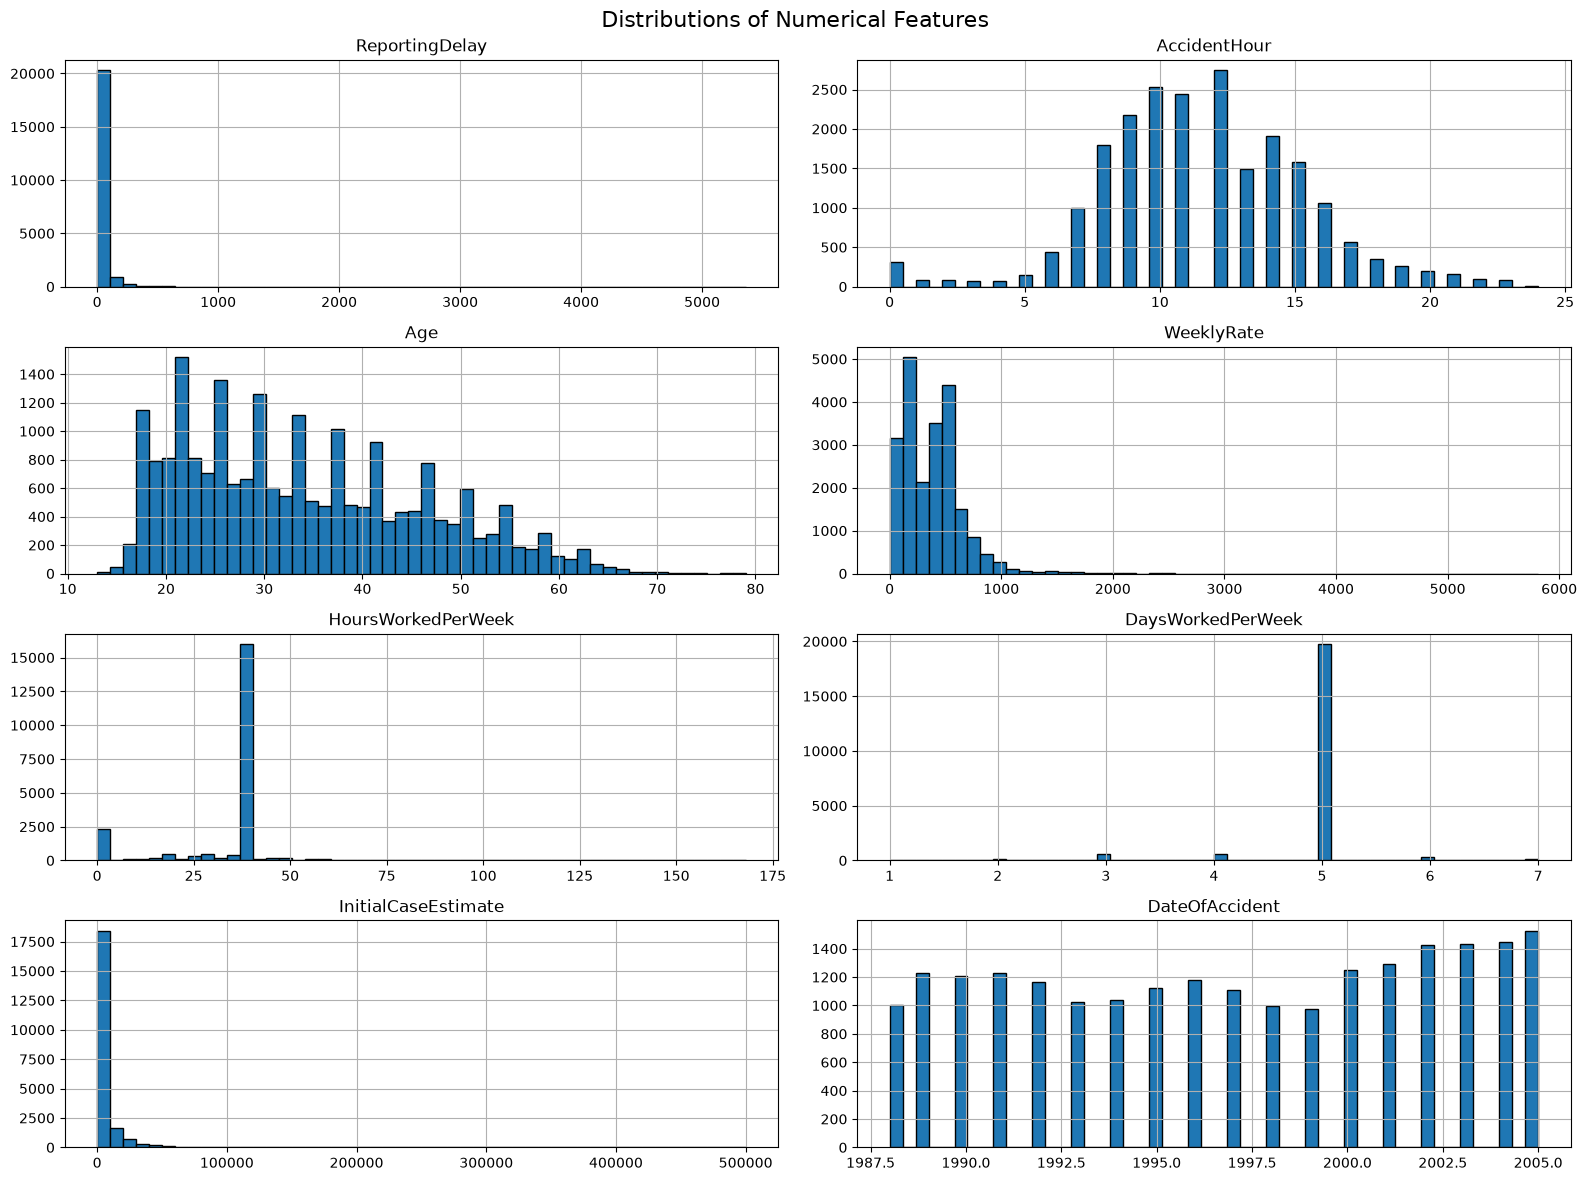

In [28]:
num_cols = [
    'ReportingDelay', 'AccidentHour', 'Age', 'WeeklyRate',
    'HoursWorkedPerWeek', 'DaysWorkedPerWeek',
    'InitialCaseEstimate', 'DateOfAccident'
]

# Create a copy for visualization
plot_df = df[num_cols].copy()

# Convert accident date to year for visualization
plot_df['DateOfAccident'] = plot_df['DateOfAccident'].dt.year

# Plot all histograms together
plot_df.hist(
    figsize=(16, 12),
    bins=50,
    layout=(4, 2),
    edgecolor='black'
)

plt.suptitle('Distributions of Numerical Features', fontsize=16)
plt.tight_layout()
plt.show()

- Reporting delay is strongly right skewed.
- AccidentHour is almost normal.
- Age is right skewed.
- WeeklyRate is right skwewed.
- HoursWorkedPerWeek, most observations are concentrated around 38–40 hours per week.
- DaysWorkedPerWeek, most observations are concentrated at five days per week.
- InitialCaseEstimate is strongly right skewed.
- Date of accident is somehow normal.

## Visualizing the categorical columns

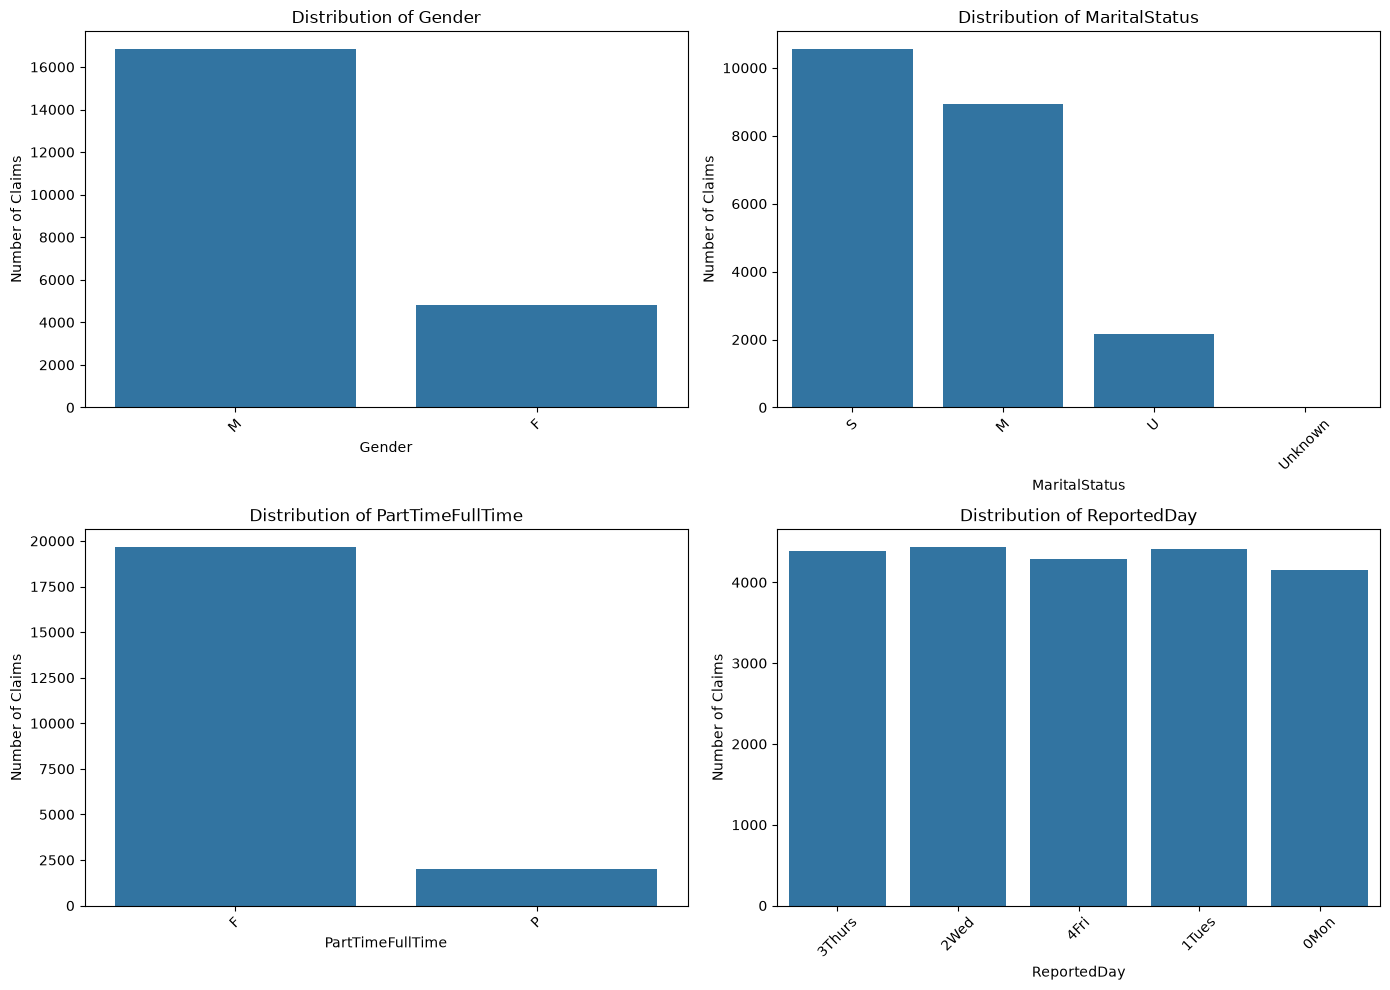

In [29]:
cat_cols = [
    'Gender',
    'MaritalStatus',
    'PartTimeFullTime',
    'ReportedDay'
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    sns.countplot(data=df, x=col, ax=axes[i])
    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Number of Claims')
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

- Male are more compared to female.
- Single people are leading, followed by Married and lastly U (unknown)
- Full time employees are so many compared to part-time employees.
- The distribution of reportedDays is almost equal

In [30]:
df['MaritalStatus'].value_counts(dropna=False)

MaritalStatus
S          10549
M           8947
U           2150
Unknown       22
Name: count, dtype: int64

### Correlation heatmap

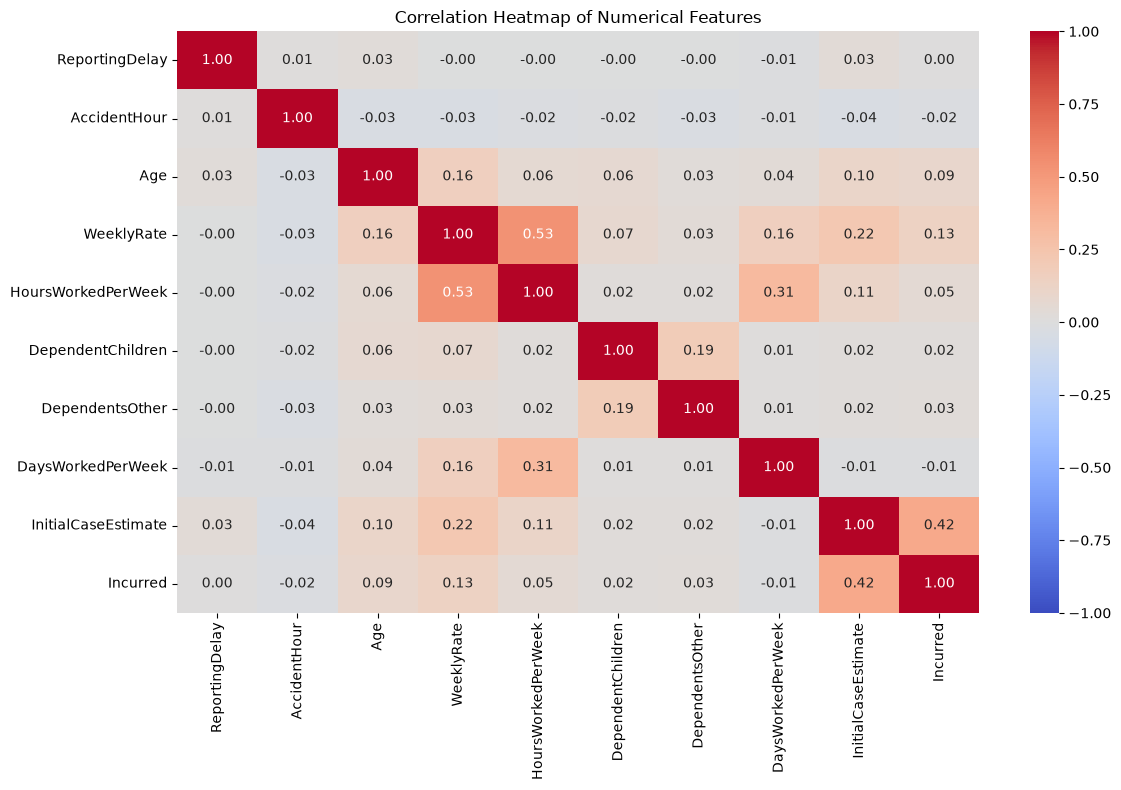

In [31]:
# Select numerical columns only
num_df = df.select_dtypes(include='number')

# Calculate correlations
corr = num_df.corr()

# Plot heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)

plt.title('Correlation Heatmap of Numerical Features')
plt.tight_layout()
plt.show()

## VIF for multicollinearity.
- VIF = 1: no multicollinearity
- VIF </= 5: Moderate multicollinearity
- VIF > 5 (or 10): High multicollinearity

In [32]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Select numerical predictor variables
vif_cols = [
    'ReportingDelay',
    'AccidentHour',
    'Age',
    'WeeklyRate',
    'HoursWorkedPerWeek',
    'DependentChildren',
    'DependentsOther',
    'DaysWorkedPerWeek',
    'InitialCaseEstimate'
]

# Prepare data for VIF
X_vif = df[vif_cols].dropna()

# Calculate VIF
vif_data = pd.DataFrame()
vif_data['Feature'] = X_vif.columns
vif_data['VIF'] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

vif_data = vif_data.sort_values('VIF', ascending=False)
vif_data.round(2)

,Feature,VIF
4,HoursWorkedPerWeek,1.52
3,WeeklyRate,1.49
7,DaysWorkedPerWeek,1.11
8,InitialCaseEstimate,1.06
5,DependentChildren,1.05
6,DependentsOther,1.04
2,Age,1.04
1,AccidentHour,1.00
0,ReportingDelay,1.00


ReportingDelay and AccidentHour have almost no multicollinearity, while the rest have a low multicollinearity

## Outlier Treatment

In [33]:
numerical_cols = [
    'ReportingDelay',
    'AccidentHour',
    'Age',
    'WeeklyRate',
    'HoursWorkedPerWeek',
    'DependentChildren',
    'DependentsOther',
    'DaysWorkedPerWeek',
    'InitialCaseEstimate',
    'Incurred'
]

outlier_results = []

for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

    outlier_results.append({
        'Feature': col,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outlier Count': len(outliers),
        'Outlier Percentage (%)': len(outliers) / len(df) * 100
    })

outlier_summary = pd.DataFrame(outlier_results)
outlier_summary.round(2)

,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage (%)
0,ReportingDelay,-28.00,84.00,2042,9.42
1,AccidentHour,1.50,21.50,584,2.70
2,Age,-4.50,71.50,12,0.06
3,WeeklyRate,-250.00,950.00,572,2.64
4,HoursWorkedPerWeek,35.00,43.00,5165,23.84
5,DependentChildren,0.00,0.00,1267,5.85
6,DependentsOther,0.00,0.00,172,0.79
7,DaysWorkedPerWeek,5.00,5.00,1934,8.93
8,InitialCaseEstimate,-10000.00,18000.00,1924,8.88
9,Incurred,-2288.16,4294.27,3397,15.68


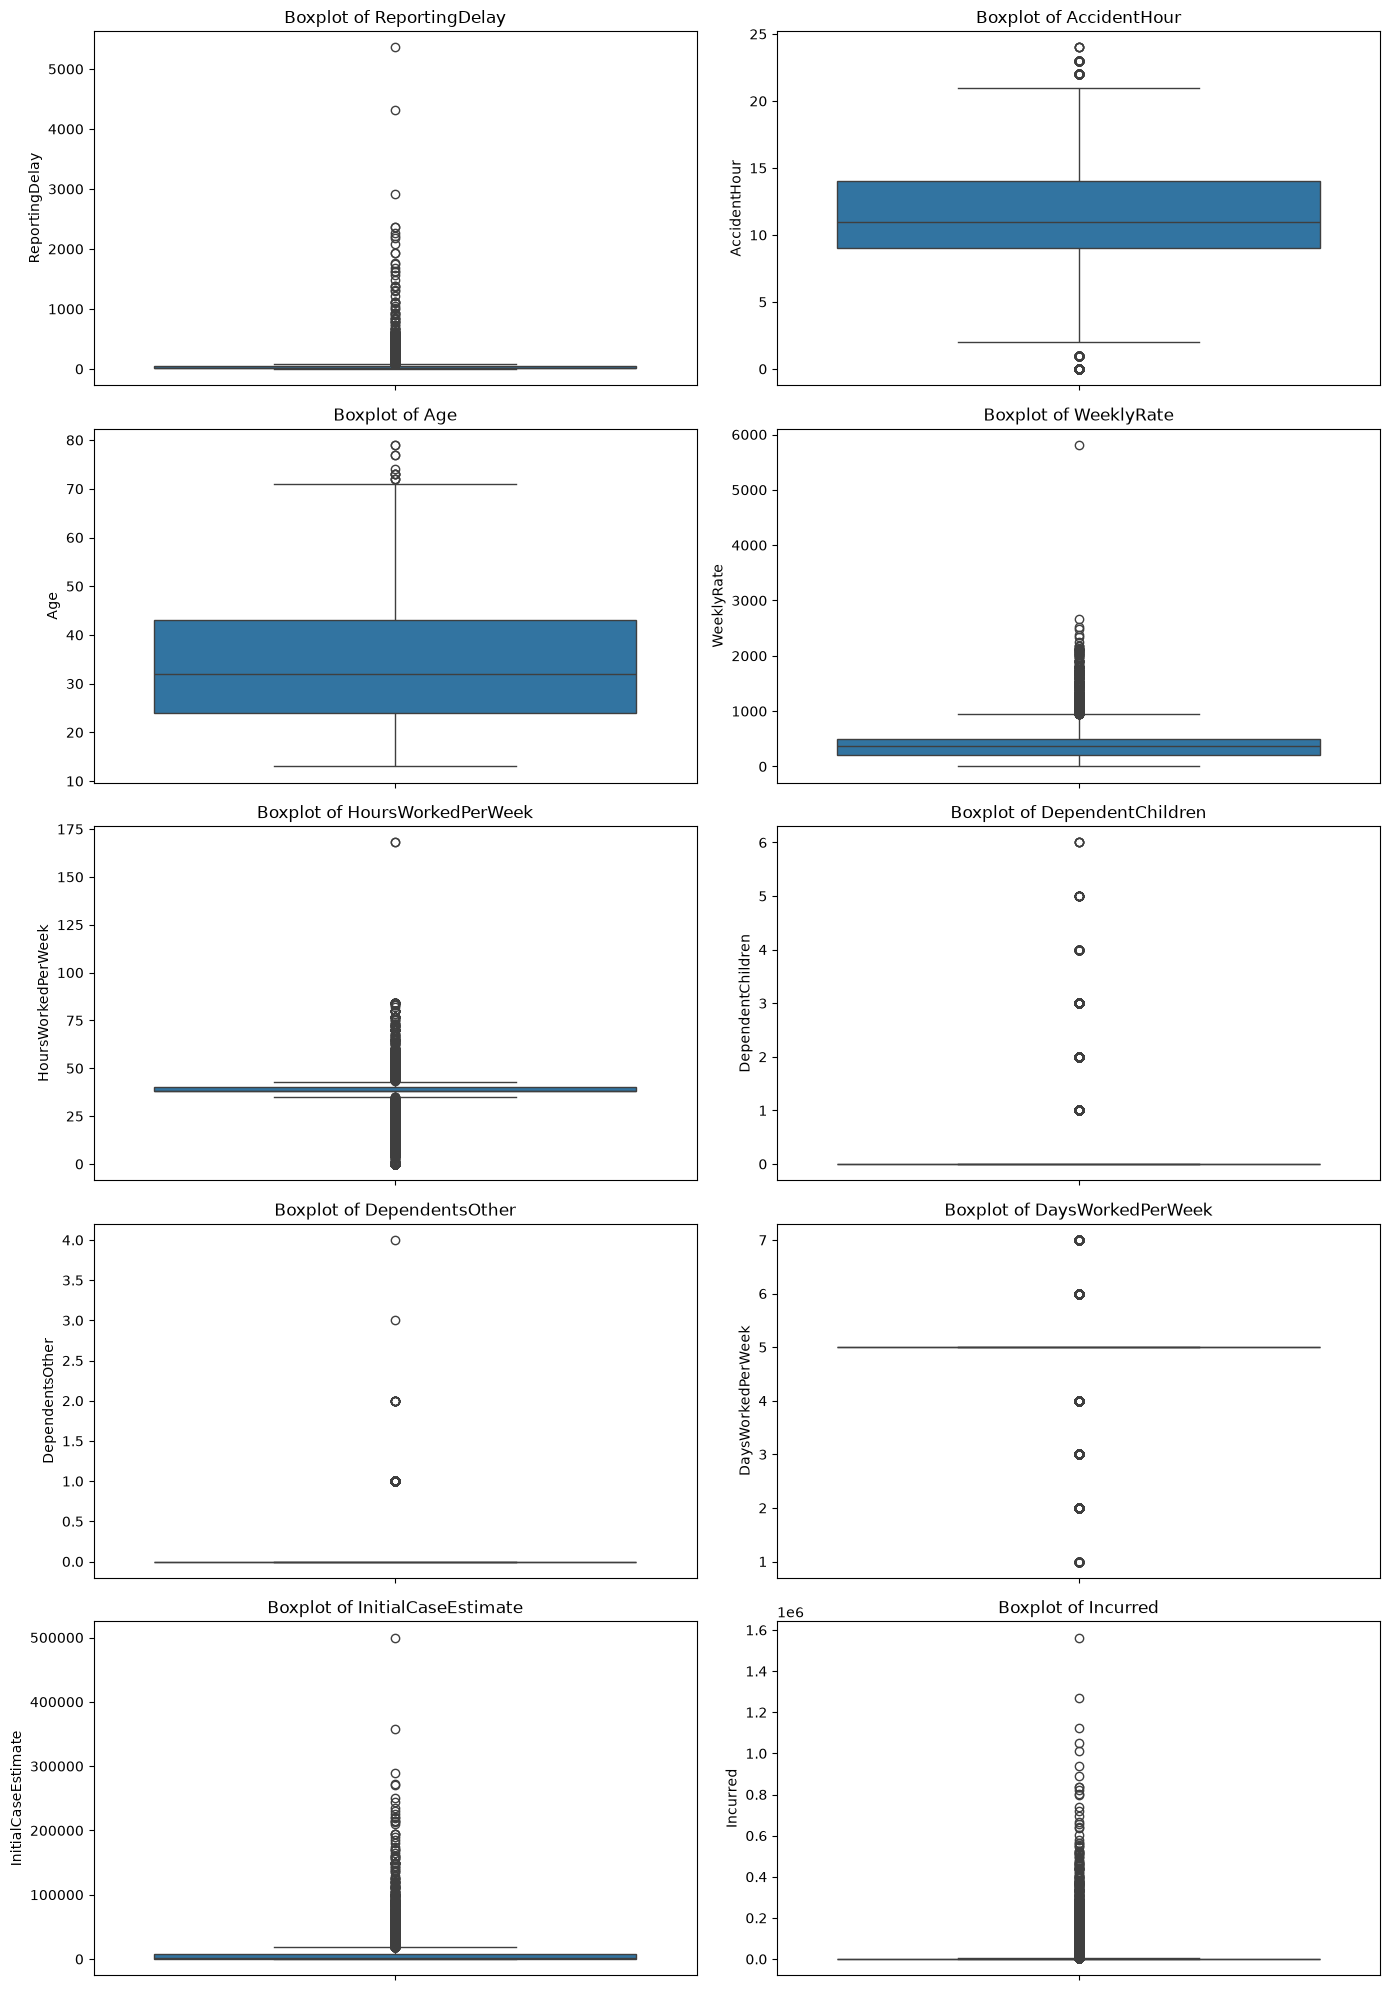

In [34]:
fig, axes = plt.subplots(5, 2, figsize=(14, 20))
axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    sns.boxplot(y=df[col], ax=axes[i])
    axes[i].set_title(f'Boxplot of {col}')
    axes[i].set_ylabel(col)

plt.tight_layout()
plt.show()

The boxplots reveal potential outliers in several numerical features, particularly ReportingDelay, WeeklyRate, HoursWorkedPerWeek, InitialCaseEstimate and Incurred. Several features, including the number of dependants and days worked per week, are naturally discrete and concentrated around particular values.

Outlier detection alone is not sufficient reason to delete observations hence the next step is to investigate implausible values and distinguish genuine extreme observations from data errors. Since Incurred is the target for claim severity prediction, unusually high claim amounts should be retained unless there is evidence that they are incorrect. If the target is later converted into low, medium and high severity classes, these extreme amounts will also influence the choice of severity thresholds.

The boxplots for DependentChildren and DependentsOther look unusual because these are count variables with many zeros. The IQR method flags legitimate nonzero values simply because most observations are zero. This does not mean those records are erroneous.

### Investigating AccidentHour

In [35]:
print("Minimum:", df['AccidentHour'].min())
print("Maximum:", df['AccidentHour'].max())

df.loc[
    (df['AccidentHour'] < 0) | (df['AccidentHour'] > 23),
    ['AccidentHour', 'DateOfAccident', 'ClaimDescription']
]

Minimum: 0
Maximum: 24


,AccidentHour,DateOfAccident,ClaimDescription
6421,24,1988-02-27,STRUCK METAL BAR STRAIN RIGHT SHOULDER INJURY
10688,24,1994-06-08,HIT ARM ON HAND LACERATION LEFT LOWER LEFT HAND
12027,24,1994-02-20,FELL FROM MACHINE LACERATION TO RIGHT ELBOW
19938,24,2003-08-04,SLIPPED KNIFE LACERATED LEFT FINGER


In the conventional 24-hour clock, valid hour values are 0–23, so 24 is outside the expected range.

 The observations have an `AccidentHour` value of 24. Since the available dataset documentation does not clarify the meaning of this value, the observations will be retained during EDA without modification. Their treatment will be reviewed during preprocessing to avoid making unsupported assumptions or unnecessarily removing data.

### Investigating WeeklyRate

In [36]:
Q1 = df['WeeklyRate'].quantile(0.25)
Q3 = df['WeeklyRate'].quantile(0.75)
IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR

print("Upper IQR bound:", upper_bound)
print("Outlier count:", (df['WeeklyRate'] > upper_bound).sum())

df.loc[
    df['WeeklyRate'] > upper_bound,
    ['WeeklyRate', 'Age', 'HoursWorkedPerWeek',
     'PartTimeFullTime', 'InitialCaseEstimate', 'Incurred']
].sort_values('WeeklyRate', ascending=False).head(15)

Upper IQR bound: 950.0
Outlier count: 572


,WeeklyRate,Age,HoursWorkedPerWeek,PartTimeFullTime,InitialCaseEstimate,Incurred
7163,5811.30,59,65.00,F,20000,5487.785455
4033,2674.00,58,56.00,F,10000,2772.844053
10900,2522.03,24,56.00,F,990,406.359345
13591,2487.00,48,38.00,F,56625,639076.468900
8727,2380.93,24,56.00,F,440,206.843762
10475,2335.00,39,84.00,F,12000,2619.844308
16043,2246.00,25,59.00,F,55000,3297.121061
1444,2178.90,39,30.00,F,1000,1227.868896
21009,2171.32,52,54.00,F,700,230.864977
6027,2168.56,54,40.00,F,500,237.940682


Outliers will be kept since they may represent legitimate observations thus scaling (Robustscaler) will be considered during the preprocessing step

### Investigating InitialCaseEstimate

In [37]:
Q1 = df['InitialCaseEstimate'].quantile(0.25)
Q3 = df['InitialCaseEstimate'].quantile(0.75)
IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR

print("Upper IQR bound:", upper_bound)
print("Outlier count:",
      (df['InitialCaseEstimate'] > upper_bound).sum())

df.loc[
    df['InitialCaseEstimate'] > upper_bound,
    ['InitialCaseEstimate', 'Incurred',
     'ClaimDescription', 'ReportingDelay']
].sort_values('InitialCaseEstimate', ascending=False).head(15)

Upper IQR bound: 18000.0
Outlier count: 1924


,InitialCaseEstimate,Incurred,ClaimDescription,ReportingDelay
4002,500000,4.599808e+05,BENDING CLEANING STRAIN LOWER BACK STRAIN LOWE...,20
8991,358000,3.963779e+05,LIFTING LOWER BACK STRAIN,94
591,290000,4.755062e+05,LIFTING REPETITIVE STRAIN BACK STRAIN LOWER BA...,40
6250,272000,1.563323e+06,FELL DOWN LOWER BACK LOWER BACK PAIN,25
7702,270000,3.963779e+05,FELL OFF LADDER BACK STRAIN RIGHT SHOULDER STRAIN,13
15479,250297,5.083576e+04,LIFTING CHILD STRAIN BACK STRAIN UPPER BACK ST...,15
7128,245000,8.253917e+03,FELL DOWN STAIRS STRAIN LEFT FINGERS,28
11562,235000,3.657718e+04,LIFTING STRAIN RIGHT KNEE,54
20412,230069,2.682134e+04,STRUCK FORKLIFT LOW BACK STRAIN,193
15047,225000,6.025641e+05,LIFTING RESIDENT LOWER BACK INJURY,49


The InitialCaseEstimate variable has 1,924 observations above the upper IQR bound of 18,000. These observations are flagged as potential outliers, but they will be retained pending further investigation because high initial claim estimates may be legitimate. Their distribution and relationship with the Incurred target will be examined before deciding on any preprocessing

Some claims have high initial estimates but much lower Incurred values. This is worth exploring, as the initial estimate may not match the final cost.

### Scatter plot for InitialCaseEstimate vs. Incurred 

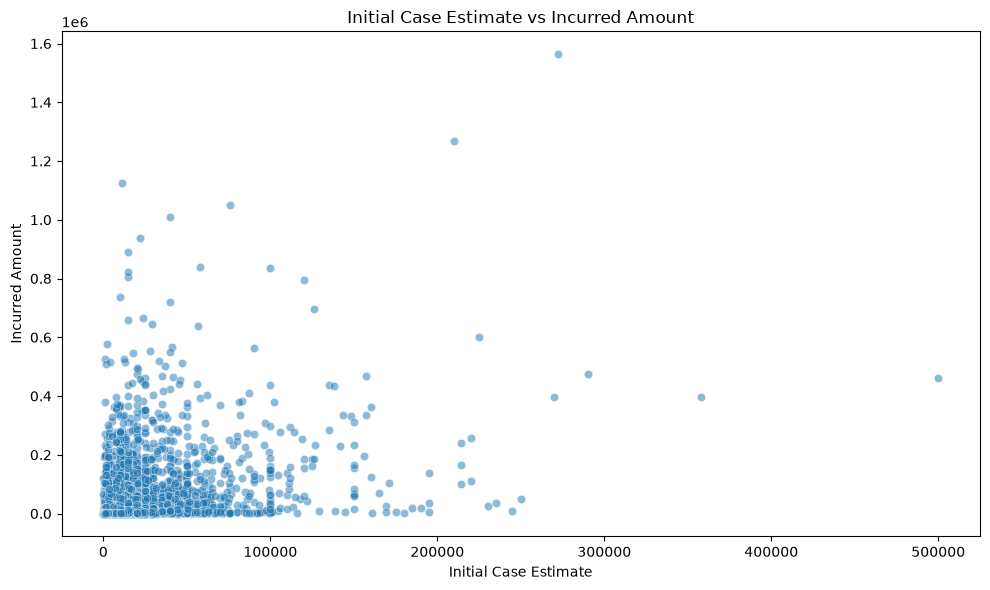

In [38]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='InitialCaseEstimate',
    y='Incurred',
    alpha=0.5
)

plt.title('Initial Case Estimate vs Incurred Amount')
plt.xlabel('Initial Case Estimate')
plt.ylabel('Incurred Amount')
plt.tight_layout()
plt.show()

- Both cases have both a low initial estimate and a low final incurred amount. 
- There are cases that were estimated very low but ended up costing a massive amount (the vertical outliers)
- 

### Investigating Incurred

In [39]:
Q1 = df['Incurred'].quantile(0.25)
Q3 = df['Incurred'].quantile(0.75)
IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR

print("Upper IQR bound:", upper_bound)
print("Outlier count:", (df['Incurred'] > upper_bound).sum())

df.loc[
    df['Incurred'] > upper_bound,
    ['Incurred', 'InitialCaseEstimate', 'ClaimDescription',
     'Age', 'ReportingDelay']
].sort_values('Incurred', ascending=False).head(15)

Upper IQR bound: 4294.26682875
Outlier count: 3397


,Incurred,InitialCaseEstimate,ClaimDescription,Age,ReportingDelay
6250,1.563323e+06,272000,FELL DOWN LOWER BACK LOWER BACK PAIN,46,25
4854,1.269778e+06,210000,LIFTING LOWER BACK STRAIN LOWER BACK STRAIN,41,13
4316,1.124836e+06,11000,LIFTING BAGS BACK STRAIN LOWER BACK PAIN,49,28
3509,1.050411e+06,76000,SLIPPED ON STEP STRAIN RIGHT KNEE BACK STRAIN,41,6
8470,1.011132e+06,40000,STRUCK FALLING BOX LOWER BACK STRAIN LEFT LEG,33,8
7554,9.373632e+05,22000,LIFTING BOX STRAINED LOWER BACK STRAIN BACK,42,40
803,8.913606e+05,14500,TWISTED BACK STRAIN LOWER BACK STRAIN,26,63
6995,8.378862e+05,58115,LIFTING TRUCK BACK STRAIN LOWER BACK STRAIN,35,16
7304,8.345769e+05,100000,FALL OVER BACK STRAIN LOWER BACK INJURY,34,15
18000,8.234933e+05,15000,FELL FROM LADDER BACK SPRAIN,33,42


### Investigating DaysWorkedPerWeek

In [40]:
print(df['DaysWorkedPerWeek'].value_counts().sort_index())

DaysWorkedPerWeek
1       62
2      177
3      580
4      635
5    19734
6      360
7      120
Name: count, dtype: int64


# **Data Preprocessing**

Converting the continuous incurred amounts into three categories: Low, Medium and High severity through a process called *target variable descretisation or binning* (the process of converting a continuous numerical target variable into a finite set of discrete classes, bins or categories) since there is an abscence of established cost thresholds. Creation of a new column named "severity' and then categorize the thresholds into 33rd and 67th percentiles to divide into the three groups such that: claims below 33rd percentile are low severity, claims above 33rd but below 67th percentile are medium severity and lastly, claims above the 67th percentile are high severity. And also create some class balance.

In [43]:
# Checking Incurred distribution
df['Incurred'].describe(percentiles=[0.33, 0.50, 0.67])

count    2.166800e+04
mean     9.630120e+03
std      4.704018e+04
min      2.220000e-15
33%      2.484248e+02
50%      4.958777e+02
67%      1.121230e+03
max      1.563323e+06
Name: Incurred, dtype: float64

In [44]:
# Calculate the severity thresholds
lower_threshold = df['Incurred'].quantile(0.33)
upper_threshold = df['Incurred'].quantile(0.67)

print("Low severity upper limit:", lower_threshold)
print("Medium severity upper limit:", upper_threshold)

Low severity upper limit: 248.42475000000013
Medium severity upper limit: 1121.22955804


In [45]:
# Creating severity categories
df['Severity'] = np.select(
    [
        df['Incurred'] <= lower_threshold,
        df['Incurred'] <= upper_threshold
    ],
    [
        'Low',
        'Medium'
    ],
    default='High'
)

In [46]:
# Check resulting classes
print(df['Severity'].value_counts())

print("\nClass percentages:")
print((df['Severity'].value_counts(normalize=True) * 100).round(2))

Severity
Medium    7366
Low       7151
High      7151
Name: count, dtype: int64

Class percentages:
Severity
Medium    33.99
Low       33.00
High      33.00
Name: proportion, dtype: float64


The classes are nearly equally represented but medium has slightly more claims.

In [47]:
df.head()

,ReportingDelay,AccidentHour,Age,WeeklyRate,Gender,MaritalStatus,HoursWorkedPerWeek,DependentChildren,DependentsOther,PartTimeFullTime,DaysWorkedPerWeek,DateOfAccident,ClaimDescription,ReportedDay,InitialCaseEstimate,Incurred,Severity
0,15,11,28,500.00,M,S,44.0,0,0,F,5,2005-10-05,STRUCK SCAFFOLDING STRAIN LOWER BACK,3Thurs,9500,151.254501,Low
1,22,5,29,500.00,M,S,38.0,0,0,F,5,2003-10-28,STRUCK KNIFE LACERATED LEFT THUMB,2Wed,11500,442.125024,Medium
2,22,7,28,197.37,M,M,16.0,0,0,P,3,2004-05-25,SLIPPED AND HIT STRAINED LEFT SHOULDER INJURY ...,2Wed,8000,1494.490505,High
3,15,12,40,0.00,M,M,0.0,1,0,F,5,1994-07-21,HIT FALLING DOOR LACERATION LEFT SHOULDER INJU...,4Fri,500,138.900000,Low
4,38,12,22,435.70,M,M,38.0,0,0,F,5,1992-06-09,STRUCK FALLING OBJECT LACERATION RIGHT RING FI...,4Fri,320,296.160000,Medium


In [48]:
# Checking if creating 'Severity' created missing values
df['Severity'].isna().sum()

np.int64(0)

### Combining 'unknown' and 'U'

In [49]:
df['MaritalStatus'] = df['MaritalStatus'].replace({
    'U': 'Unknown',
    'Unknown': 'Unknown'
})

In [50]:
print(df['MaritalStatus'].value_counts())

MaritalStatus
S          10549
M           8947
Unknown     2172
Name: count, dtype: int64
